# Cosine potential: fixed auxiliary, time-block adaptive, and physical heuristic

Put this notebook beside your `two_bsde` folder containing `config.py`,
`problem.py`, `dynamics.py`, `geometry.py`, `hamiltonian.py`,
`twoBsdeStructure.py`, `networks.py`, `training.py`, `evaluation.py`, and
`__init__.py`. The upload suffixes such as `(2)` and `(3)` are not part of
the module names. Replace `config.py` and `dynamics.py` with the accompanying versions, then
restart the kernel before running. The remaining package files are unchanged.

Use the two supplied solver classes and training functions. The comparison
is limited to the value/cost and control decisions.

Known $\Theta=2\pi$, hidden $X\in\{0.5,1,1.5\}$ with prior
$(0.25,0.5,0.25)$, $D_0=1/2$, and $k_BT_{\rm bath}=1$ specify the drift.
Choose the observation noise independently:
$$dY_t=-\tfrac12 X u_t\sin(Y_t)\,dt+\sigma\,dW_t,\qquad \sigma=0.1,\qquad u_t\in\{-1,1\}.$$
Take $Y_0=1$, $T=1$, and the requested target $r(t)=1+0.5t^2$:
$$J(u)=\mathbb E\left[\int_0^T(Y_t-r(t))^2dt+(Y_T-r(T))^2\right].$$
The drift and target are unchanged. `observation_noise_std` scales the observation
noise independently of the drift coefficient `D0`. The posterior uses
$p_i(h_i-\bar h)/\sigma$ with the same standard innovation Brownian motion.
The default noise setting is 1.0 for compatibility; this notebook selects 0.1.
The same two solvers and notebook structure are retained.

In [1]:
from pathlib import Path
from dataclasses import replace
import math
import sys

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from two_bsde.config import ModelConfig, HamiltonianConfig, TrainingConfig
from two_bsde.problem import BayesianControlProblem
from two_bsde.geometry import make_simplex_tangent_basis, SimplexGeometry
from two_bsde.hamiltonian import HamiltonianOptimizer
from two_bsde.twoBsdeStructure import (
    GeometricClassicalFixedAux2BSDE, GeometricTimeBlockAdaptive2BSDE,
)
from two_bsde.training import train, train_time_blocks
from two_bsde.evaluation import evaluate, evaluate_time_blocks

DTYPE = torch.float64
DEVICE = torch.device("cpu")
torch.set_num_threads(1)

## Configuration

The network sizes, epoch count, and fixed-model training settings are retained.
The fine grid increases from 50 to 200 steps because noise 0.1 makes posterior
updates faster; this reduced posterior clipping markedly in simulation checks. The adaptive model uses the existing `num_blocks=1`
option, balanced learning rates, and a stronger existing gradient-consistency
weight. The single shared network is still evaluated at every fine time step;
controls remain pathwise and are recomputed at every step.


In [2]:
config = ModelConfig(
    horizon=1.0,
    hidden_dim=1,
    observation_dim=1,
    observation_noise_std=0.1,
    control_dim=1,
    num_hidden_states=3,
    num_time_steps=200,  # finer Euler grid for faster posterior updates at noise 0.1
    network_width=64,
    network_depth=3,
    value_initial_guess=0.01,
    gamma_initial_scale=0.01,
)

ham_config = HamiltonianConfig(num_starts=1)
training_config = TrainingConfig(
    epochs=1500,
    batch_size=128,
    learning_rate=1e-4,
    initial_value_lr=3e-3,
    gradient_clip=10.0,
    value_loss_weight=1.0,
    gradient_loss_weight=1.0,
)

# Existing configuration only: this rate trains all adaptive value-head weights.
block_training_config = replace(
    training_config, learning_rate=1e-3, initial_value_lr=1e-3,
)

NUM_TEST_PATHS = 500
NUM_HEURISTIC_PATHS = 10000

basis = make_simplex_tangent_basis(
    config.num_hidden_states, dtype=DTYPE, device=DEVICE
)
geometry = SimplexGeometry(observation_dim=1, basis=basis)

## Concrete problem

The original optimizer tests a grid on $[-1,1]$. The endpoints are exactly the
two admissible actions. As in the original notebook, the running cost is finite
at $u=\pm1$ and $+\infty$ elsewhere. No optimizer replacement is needed.

The current supplied adaptive solver already uses each path's own minimizer.
Its old control-fraction arguments are ignored and are therefore omitted.


In [3]:
class CosineTrackingProblem(BayesianControlProblem):
    def __init__(self, config, theta=2 * math.pi):
        super().__init__(config)
        self.theta = float(theta)  # known, not part of the posterior
        self.D0 = 0.5              # drift coefficient; observation noise is configured separately
        self.thermal_energy = 1.0
        self.x_support = torch.tensor(
            [[0.5], [1.0], [1.5]], dtype=DTYPE, device=DEVICE
        )
        self.initial_observation = torch.tensor([1.0], dtype=DTYPE, device=DEVICE)
        self.initial_posterior = torch.tensor([0.25, 0.5, 0.25], dtype=DTYPE, device=DEVICE)
        self.control_low = torch.tensor([-1.0], dtype=DTYPE, device=DEVICE)
        self.control_high = torch.tensor([1.0], dtype=DTYPE, device=DEVICE)
        self.auxiliary_control_path = torch.ones(
            config.num_time_steps, 1, dtype=DTYPE, device=DEVICE
        )  # fixed-auxiliary model uses u_aux = +1
        self.validate(config)

    @staticmethod
    def target(time):
        return 1.0 + 0.5 * time**2

    def sensor(self, control, observation):
        # Output [..., num_hidden_states, observation_dim] = [..., 3, 1].
        x = self.x_support[:, 0].to(observation)
        coefficient = 2 * math.pi * self.D0 / (self.thermal_energy * self.theta)
        phase = torch.sin(2 * math.pi * observation[..., 0] / self.theta)
        drift = -coefficient * control[..., 0] * phase
        return (drift[..., None] * x)[..., None]

    def running_cost(self, state, control, time=None):
        if time is None:
            raise ValueError("This time-dependent running cost requires time.")
        tracking_cost = (state[..., 0] - self.target(time)).square()
        admissible = (control[..., 0] == -1) | (control[..., 0] == 1)
        return torch.where(
            admissible, tracking_cost, torch.full_like(tracking_cost, float("inf"))
        )

    def terminal_cost(self, state):
        return (state[..., 0] - self.target(self.config.horizon)).square()


problem = CosineTrackingProblem(config)
S0 = torch.cat((problem.initial_observation, problem.initial_posterior))

## Hamiltonian optimizers

The supplied package already passes `time` to the Hamiltonian and running cost.
Use its original optimizer directly; no clock adapter or forward hooks are needed.


In [4]:
fixed_hamiltonian = HamiltonianOptimizer(
    problem=problem, model_config=config,
    optimizer_config=ham_config, geometry=geometry,
)
block_problem = CosineTrackingProblem(config)
block_hamiltonian = HamiltonianOptimizer(
    problem=block_problem, model_config=config,
    optimizer_config=ham_config, geometry=geometry,
)


## Fixed-auxiliary model

In [5]:
torch.manual_seed(2026)
fixed_model = GeometricClassicalFixedAux2BSDE(
    problem=problem, config=config, geometry=geometry,
    hamiltonian_optimizer=fixed_hamiltonian,
).to(dtype=DTYPE, device=DEVICE)

fixed_history = train(
    fixed_model, model_config=config,
    training_config=training_config, verbose=True,
)

epoch=   1  total_loss=1.824e+00, where  value_loss=1.033e+00  and gradient_loss=7.909e-01  V0=0.013000  corr_rate=0.00e+00
epoch= 150  total_loss=2.139e-02, where  value_loss=1.161e-02  and gradient_loss=9.778e-03  V0=0.304499  corr_rate=0.00e+00
epoch= 300  total_loss=4.069e-03, where  value_loss=1.560e-03  and gradient_loss=2.509e-03  V0=0.312943  corr_rate=0.00e+00
epoch= 450  total_loss=2.097e-03, where  value_loss=8.816e-04  and gradient_loss=1.216e-03  V0=0.309011  corr_rate=0.00e+00
epoch= 600  total_loss=3.671e-03, where  value_loss=2.595e-03  and gradient_loss=1.076e-03  V0=0.305773  corr_rate=0.00e+00
epoch= 750  total_loss=1.679e-03, where  value_loss=1.027e-03  and gradient_loss=6.528e-04  V0=0.303987  corr_rate=0.00e+00
epoch= 900  total_loss=1.727e-03, where  value_loss=9.501e-04  and gradient_loss=7.766e-04  V0=0.302221  corr_rate=0.00e+00
epoch=1050  total_loss=1.443e-03, where  value_loss=8.906e-04  and gradient_loss=5.520e-04  V0=0.300759  corr_rate=0.00e+00
epoch=12

## Time-block adaptive model

The model and training function are unchanged. Stronger gradient consistency
encourages the value-network gradient to agree with propagated $Z$; it does
not guarantee agreement of their Hessians. Both implemented policies are
therefore evaluated separately below.


In [6]:
torch.manual_seed(2026)
block_model = GeometricTimeBlockAdaptive2BSDE(
    problem=block_problem, config=config, geometry=geometry,
    hamiltonian_optimizer=block_hamiltonian,
    num_blocks=1,
    track_gradient_consistency=True,
).to(dtype=DTYPE, device=DEVICE)

block_history = train_time_blocks(
    block_model, training_config=block_training_config,
    consistency_weight=1.0,
    boundary_weight=0.1,
    gradient_consistency_weight=1.0,
    sample_start_times=False,
    verbose=True,
)

epoch=   1  start_step=  0  total_loss=5.361e-02  terminal_value=9.324e-03  terminal_gradient=4.329e-02  consistency=1.320e-04  boundary=-0.000e+00  mean_start_value=-0.003905
epoch= 150  start_step=  0  total_loss=1.566e-03  terminal_value=1.276e-04  terminal_gradient=6.391e-04  consistency=4.865e-05  boundary=0.000e+00  mean_start_value=0.047720
epoch= 300  start_step=  0  total_loss=3.710e-04  terminal_value=1.070e-04  terminal_gradient=1.455e-04  consistency=2.975e-05  boundary=0.000e+00  mean_start_value=0.034389
epoch= 450  start_step=  0  total_loss=1.911e-04  terminal_value=5.173e-05  terminal_gradient=7.842e-05  consistency=1.995e-05  boundary=0.000e+00  mean_start_value=0.037541
epoch= 600  start_step=  0  total_loss=2.369e-04  terminal_value=1.102e-04  terminal_gradient=5.957e-05  consistency=3.116e-05  boundary=0.000e+00  mean_start_value=0.044512
epoch= 750  start_step=  0  total_loss=3.322e-04  terminal_value=1.321e-04  terminal_gradient=1.355e-04  consistency=2.775e-05  

## A physical tracking heuristic

Push toward a weighted average of the remaining target positions and the
terminal target:
$$q(t)=\frac{\int_t^T r(s)\,ds+r(T)}{T-t+1},\qquad
u_{\rm h}(t,y)=\begin{cases}+1,&(y-q(t))\sin(y)>0,\\-1,&\text{otherwise.}\end{cases}$$
For $r(t)=1+0.5t^2$, the integral is $(T-t)+(T^3-t^3)/6$.
With $T=1$, $q(0)=4/3$ and $q(T)=1.5$.

This rule anticipates the moving target. It chooses the force that decreases
the approximate remaining cost
$Q(t,y)=\int_t^T(y-r(s))^2ds+(y-r(T))^2$ fastest. Since $X>0$, its magnitude
does not change the direction of that force. The controller uses only time
and the observed position, never the sampled hidden $X$.

Estimate its actual cost by physical Euler simulations: sample $X$ once per
path from the prior, then keep it fixed. This is an admissible heuristic, not
an analytic optimal policy. All methods use the same fine time grid.

In [7]:
def heuristic_control(time, observation):
    y = observation[..., 0]
    T = config.horizon
    future_target_integral = (T - time) + (T**3 - time**3) / 6.0
    aim = (future_target_integral + problem.target(T)) / (T - time + 1.0)
    phase = torch.sin(2 * math.pi * y / problem.theta)
    return torch.where(
        (y - aim) * phase > 0, torch.ones_like(y), -torch.ones_like(y)
    )[..., None]


@torch.no_grad()
def evaluate_heuristic(num_paths):
    hidden_index = torch.multinomial(problem.initial_posterior, num_paths, replacement=True)
    path_index = torch.arange(num_paths, device=DEVICE)
    y = problem.initial_observation.expand(num_paths, -1).clone()
    cost = torch.zeros(num_paths, dtype=DTYPE, device=DEVICE)
    controls = []
    for step in range(config.num_time_steps):
        time = step * config.dt
        u = heuristic_control(time, y)
        cost += (y[..., 0] - problem.target(time)).square() * config.dt
        # Hidden X is used by the environment, not by heuristic_control.
        drift = problem.sensor(u, y)[path_index, hidden_index, :]
        y = y + drift * config.dt + config.observation_noise_std * math.sqrt(config.dt) * torch.randn_like(y)
        controls.append(u)
    cost += (y[..., 0] - problem.target(config.horizon)).square()
    return {"cost": cost, "u_path": torch.stack(controls, dim=1)}



heuristic_eval = evaluate_heuristic(NUM_HEURISTIC_PATHS)
heuristic_value = heuristic_eval["cost"].mean().item()
heuristic_se = heuristic_eval["cost"].std(unbiased=True).item() / math.sqrt(NUM_HEURISTIC_PATHS)

## Compare the value and control decisions

The neural values and Monte Carlo policy costs are distinct quantities. A low
learned value alone does not establish a good policy. The table retains the
original value/heuristic comparison and adds two costs already provided by
the supplied adaptive evaluator:

- **Propagated-control policy:** the actual controls used by the adaptive
  forward rollout, based on propagated $Z$ and its learned $\Gamma$.
- **Value-network feedback:** `rollout_policy`, based on derivatives of $v_j$.

The control plots still compare minimizers and the heuristic at the same
states. Fixed-model states follow its specified auxiliary control; adaptive
states follow its own pathwise minimizers. The fixed feedback reconstruction
in the last cell remains an approximation, not a certified optimal policy.

Cost standard errors describe Monte Carlo uncertainty only. These evaluations
use independent samples, so no paired-error claim is made. Smaller observation noise reduces path fluctuations, while the bounded drift
still limits how closely the moving target can be followed. Brownian increments
passed to the solvers retain variance `dt`; the diffusion matrix applies the
noise coefficient to the observation and its reciprocal to the posterior.

The earlier benchmark used observation noise 1.0 and does not describe this
small-noise problem. Retrain both models with the current coefficient before
interpreting the values or policies. The BSDE terminal residual is distinct
from the tracking error of $Y$.


In [8]:
fixed_eval = evaluate(fixed_model, num_paths=NUM_TEST_PATHS)

block_eval = evaluate_time_blocks(
    block_model, num_paths=NUM_TEST_PATHS, evaluate_policy=True
)

fixed_paths = fixed_eval.paths
block_paths = block_eval.paths
times_tensor = torch.arange(config.num_time_steps, dtype=DTYPE, device=DEVICE) * config.dt

for paths in (fixed_paths, block_paths):
    assert torch.isfinite(paths["R_T"]).all()
    for name in ("u_star_path", "u_aux_path"):
        u = paths[name]
        assert torch.all((u == -1) | (u == 1)), f"Nonbinary {name}"
assert torch.isfinite(heuristic_eval["cost"]).all()
assert torch.all((heuristic_eval["u_path"] == -1) | (heuristic_eval["u_path"] == 1))

fixed_controls = fixed_paths["u_star_path"][..., 0].detach().cpu().numpy()
block_controls = block_paths["u_star_path"][..., 0].detach().cpu().numpy()
heuristic_on_fixed = heuristic_control(
    times_tensor, fixed_paths["S_path"][:, :-1, :1]
)[..., 0].detach().cpu().numpy()
heuristic_on_block = heuristic_control(
    times_tensor, block_paths["S_path"][:, :-1, :1]
)[..., 0].detach().cpu().numpy()

with torch.no_grad():
    fixed_value = fixed_model.initial_value.item()
    block_value = block_model.value(0.0, S0).item()

adaptive_cost = block_paths["raw_auxiliary_cost"]
feedback_cost = block_paths["policy"]["policy_cost"]
adaptive_se = adaptive_cost.std(unbiased=True).item() / math.sqrt(NUM_TEST_PATHS)
feedback_se = feedback_cost.std(unbiased=True).item() / math.sqrt(NUM_TEST_PATHS)

comparison = pd.DataFrame({
    "Method": ["Fixed auxiliary", "Time-block adaptive", "Physical heuristic",
               "Adaptive propagated policy", "Adaptive value-network feedback"],
    "Quantity": ["Estimated V(0, S0)", "Estimated V(0, S0)", "Policy cost J(u_h)",
                 "Executed policy cost", "Executed policy cost"],
    "Value / cost": [fixed_value, block_value, heuristic_value,
                     adaptive_cost.mean().item(), feedback_cost.mean().item()],
    "MC standard error": [np.nan, np.nan, heuristic_se, adaptive_se, feedback_se],
    "Initial control": [fixed_controls[0, 0], block_controls[0, 0],
                        heuristic_eval["u_path"][0, 0, 0].item(), block_controls[0, 0],
                        block_paths["policy"]["u_path"][0, 0, 0].item()],
})
comparison

,Method,Quantity,Value / cost,MC standard error,Initial control
0,Fixed auxiliary,"Estimated V(0, S0)",0.296803,NaN,-1.0
1,Time-block adaptive,"Estimated V(0, S0)",0.039640,NaN,-1.0
2,Physical heuristic,Policy cost J(u_h),0.042420,0.000535,-1.0
3,Adaptive propagated policy,Executed policy cost,0.034381,0.002092,-1.0
4,Adaptive value-network feedback,Executed policy cost,0.037796,0.002234,-1.0


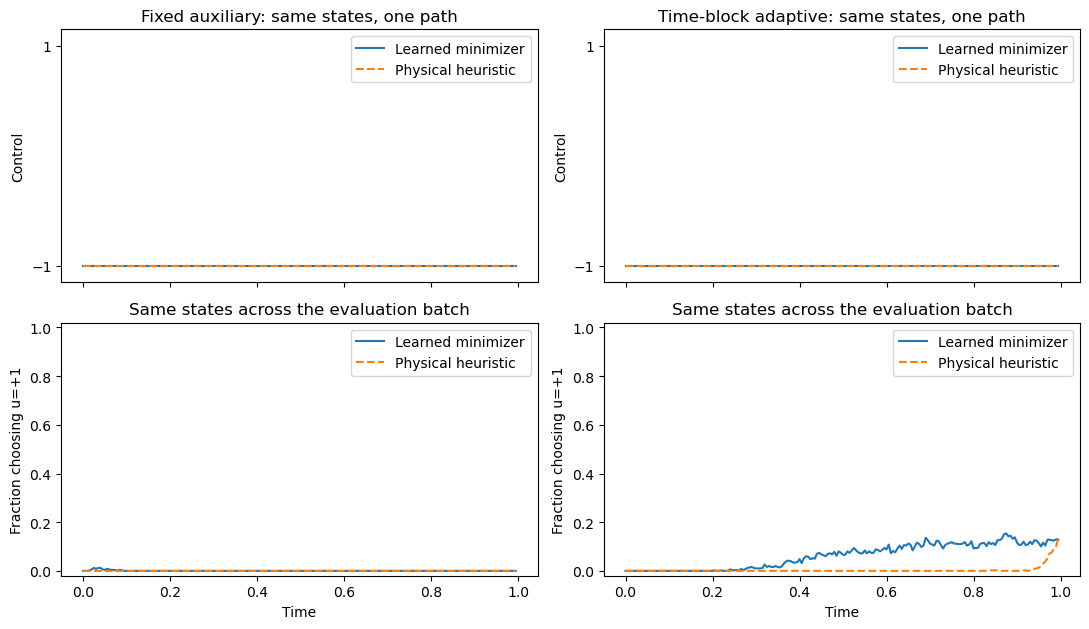

In [9]:
times = times_tensor.cpu().numpy()
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True)
for col, (name, learned, physical) in enumerate([
    ("Fixed auxiliary", fixed_controls, heuristic_on_fixed),
    ("Time-block adaptive", block_controls, heuristic_on_block),
]):
    axes[0, col].step(times, learned[0], where="post", label="Learned minimizer")
    axes[0, col].step(times, physical[0], where="post", linestyle="--", label="Physical heuristic")
    axes[0, col].set(title=f"{name}: same states, one path",
                     ylabel="Control", yticks=[-1, 1], ylim=(-1.15, 1.15))
    axes[0, col].legend()
    axes[1, col].plot(times, (learned == 1).mean(axis=0), label="Learned minimizer")
    axes[1, col].plot(times, (physical == 1).mean(axis=0), linestyle="--", label="Physical heuristic")
    axes[1, col].set(xlabel="Time", ylabel="Fraction choosing u=+1",
                     title="Same states across the evaluation batch", ylim=(-0.02, 1.02))
    axes[1, col].legend()
plt.tight_layout()
plt.show()

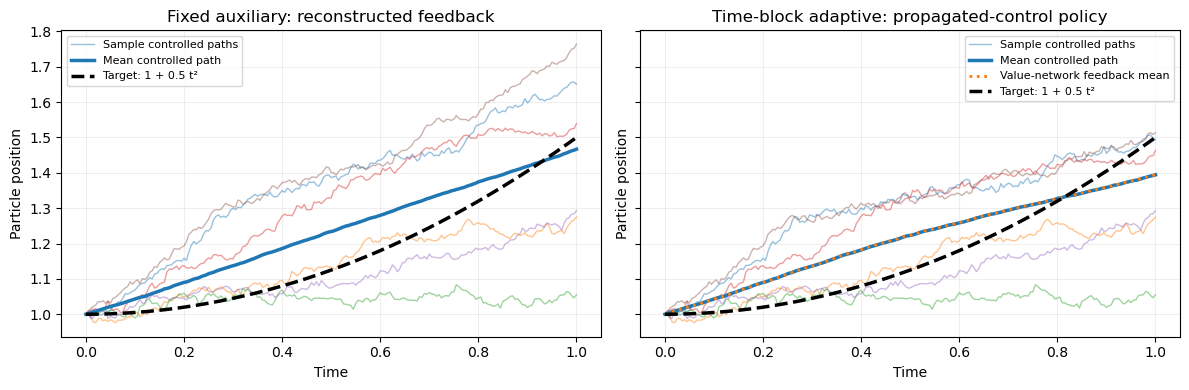

In [10]:
from two_bsde.dynamics import state_dynamics, stabilise_state


@torch.no_grad()
def rollout_fixed_feedback(model, innovations, num_references=8):
    cfg = model.config
    batch = innovations.shape[0]
    generator = torch.Generator(device=innovations.device).manual_seed(2030)
    reference_noise = math.sqrt(cfg.dt) * torch.randn(
        num_references, cfg.num_time_steps, cfg.observation_dim,
        dtype=innovations.dtype, device=innovations.device, generator=generator,
    )
    # Independent auxiliary references define a fixed, nonanticipating policy.
    references = model(reference_noise, return_paths=True)
    state = references["S_path"][0, 0].expand(batch, -1).clone()
    states, controls = [state], []

    for step in range(cfg.num_time_steps):
        if step == 0:
            Z = model.initial_gradient().expand(batch, -1)
            Gamma = model.initial_gamma().expand(batch, -1, -1)
        else:
            ref_state = references["S_path"][:, step]
            ref_Z = references["Z_path"][:, step]
            ref_Gamma = references["Gamma_path"][:, step]
            displacement = state[:, None, :] - ref_state[None, :, :]
            midpoints = 0.5 * (state[:, None, :] + ref_state[None, :, :])
            _, mid_Gamma = model.blocks[step - 1](midpoints.reshape(-1, cfg.state_dim))
            mid_Gamma = mid_Gamma.reshape(batch, num_references, cfg.state_dim, cfg.state_dim)
            _, Gamma = model.blocks[step - 1](state)
            integrated_Gamma = (ref_Gamma[None] + 4 * mid_Gamma + Gamma[:, None]) / 6
            # D V(s) = Z_ref + integral Gamma(s_ref + a*(s-s_ref))*(s-s_ref) da.
            Z = (ref_Z[None] + torch.einsum(
                "bmij,bmj->bmi", integrated_Gamma, displacement
            )).mean(dim=1)
            Z = model.geometry.project_gradient(Z)

        _, control = model.hamiltonian_optimizer.minimise(state, Z, Gamma, time=step * cfg.dt)
        drift, sigma, _ = state_dynamics(
            state, control, problem=model.problem, config=cfg, geometry=model.geometry
        )
        state = state + drift * cfg.dt + torch.einsum(
            "bia,ba->bi", sigma, innovations[:, step]
        )
        state, _ = stabilise_state(state, config=cfg)
        states.append(state)
        controls.append(control)
    return {"S_path": torch.stack(states, dim=1), "u_path": torch.stack(controls, dim=1)}


NUM_TRACKING_PATHS = 256
NUM_SHOWN_PATHS = 6
torch.manual_seed(2028)
tracking_innovations = math.sqrt(config.dt) * torch.randn(
    NUM_TRACKING_PATHS, config.num_time_steps, config.observation_dim,
    dtype=DTYPE, device=DEVICE,
)
fixed_tracking = rollout_fixed_feedback(fixed_model, tracking_innovations)
# Plot the same propagated-control policy used by the adaptive forward model.
with torch.no_grad():
    block_tracking = block_model(tracking_innovations, return_paths=True)
block_feedback_tracking = block_model.rollout_policy(tracking_innovations)

tracking_times = np.linspace(0.0, config.horizon, config.num_time_steps + 1)
tracking_fig, tracking_axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, name, rollout in zip(tracking_axes, [
    "Fixed auxiliary: reconstructed feedback",
    "Time-block adaptive: propagated-control policy",
], [fixed_tracking, block_tracking]):
    positions = rollout["S_path"][..., 0].detach().cpu().numpy()
    for i in range(min(NUM_SHOWN_PATHS, NUM_TRACKING_PATHS)):
        ax.plot(tracking_times, positions[i], alpha=0.45, linewidth=1,
                label="Sample controlled paths" if i == 0 else None)
    ax.plot(tracking_times, positions.mean(axis=0), color="tab:blue", linewidth=2.5,
            label="Mean controlled path")
    if rollout is block_tracking:
        feedback_mean = block_feedback_tracking["S_path"][..., 0].mean(0).cpu().numpy()
        ax.plot(tracking_times, feedback_mean, color="tab:orange", linestyle=":",
                linewidth=2, label="Value-network feedback mean")
    ax.plot(tracking_times, problem.target(tracking_times), "k--", linewidth=2.5,
            label="Target: 1 + 0.5 t²")
    ax.set(title=name, xlabel="Time", ylabel="Particle position")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
tracking_fig.tight_layout()
plt.show()